# Machine Learning 
## Name: Nidhi Dharme
## Class: A-A1-16

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings('ignore')

In [4]:
df=pd.read_csv('Wholesale customers data.csv')

print("First 5 Rows:")
print(df.head())


First 5 Rows:
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185


In [5]:
print("Dataset Shape:",df.shape)

Dataset Shape: (440, 8)


In [6]:
print("Dataset Information:")
print(df.info())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB
None


In [7]:
print("Statistical Description:")
print(df.describe())

Statistical Description:
          Channel      Region          Fresh          Milk       Grocery  \
count  440.000000  440.000000     440.000000    440.000000    440.000000   
mean     1.322727    2.543182   12000.297727   5796.265909   7951.277273   
std      0.468052    0.774272   12647.328865   7380.377175   9503.162829   
min      1.000000    1.000000       3.000000     55.000000      3.000000   
25%      1.000000    2.000000    3127.750000   1533.000000   2153.000000   
50%      1.000000    3.000000    8504.000000   3627.000000   4755.500000   
75%      2.000000    3.000000   16933.750000   7190.250000  10655.750000   
max      2.000000    3.000000  112151.000000  73498.000000  92780.000000   

             Frozen  Detergents_Paper    Delicassen  
count    440.000000        440.000000    440.000000  
mean    3071.931818       2881.493182   1524.870455  
std     4854.673333       4767.854448   2820.105937  
min       25.000000          3.000000      3.000000  
25%      742.250000 

In [8]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64


In [9]:
print("Duplicate Records:",df.duplicated().sum())

Duplicate Records: 0


In [12]:
print(df.columns.tolist())

['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']


In [13]:
df.columns=df.columns.str.strip()

print(df.columns.tolist())

['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']


In [16]:
X=df[['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicassen']]

print("Selected Features:")
print(X.head())

print("\nDataset Shape:",X.shape)

Selected Features:
   Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0  12669  9656     7561     214              2674        1338
1   7057  9810     9568    1762              3293        1776
2   6353  8808     7684    2405              3516        7844
3  13265  1196     4221    6404               507        1788
4  22615  5410     7198    3915              1777        5185

Dataset Shape: (440, 6)


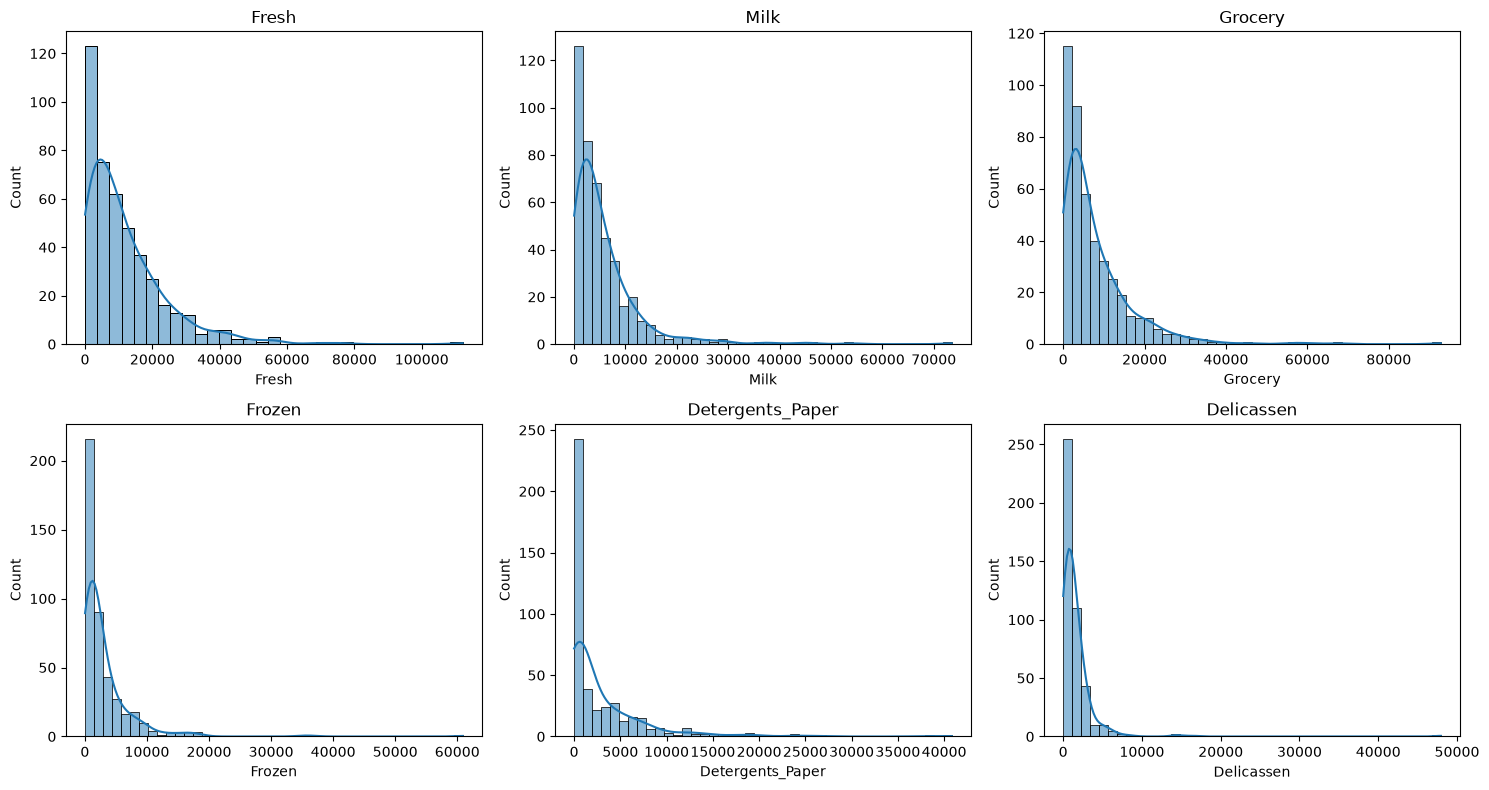

In [17]:
plt.figure(figsize=(15,8))

for i,col in enumerate(X.columns):
    plt.subplot(2,3,i+1)
    sns.histplot(X[col],kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

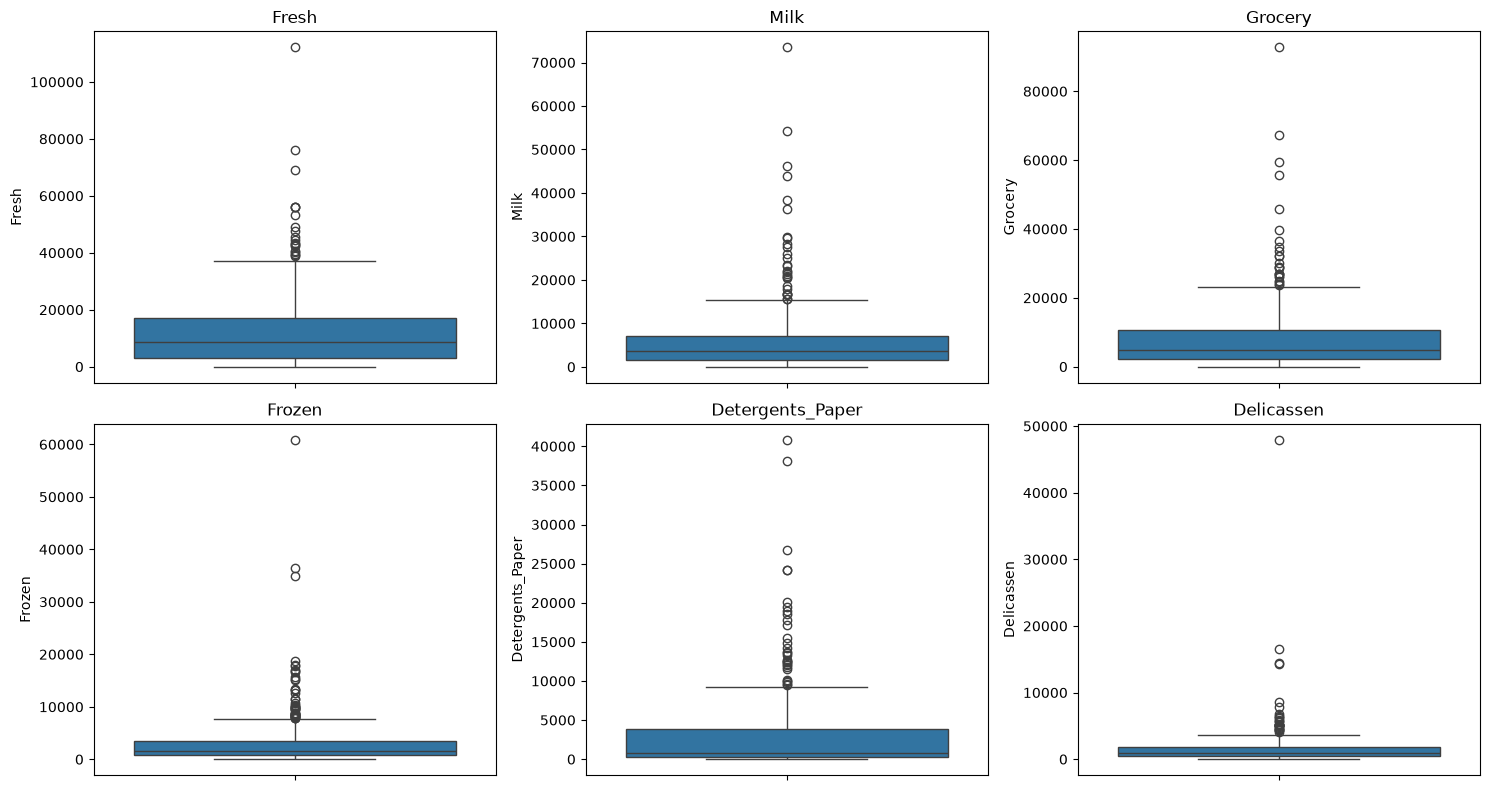

In [18]:
plt.figure(figsize=(15,8))

for i,col in enumerate(X.columns):
    plt.subplot(2,3,i+1)
    sns.boxplot(y=X[col])
    plt.title(col)

plt.tight_layout()
plt.show()

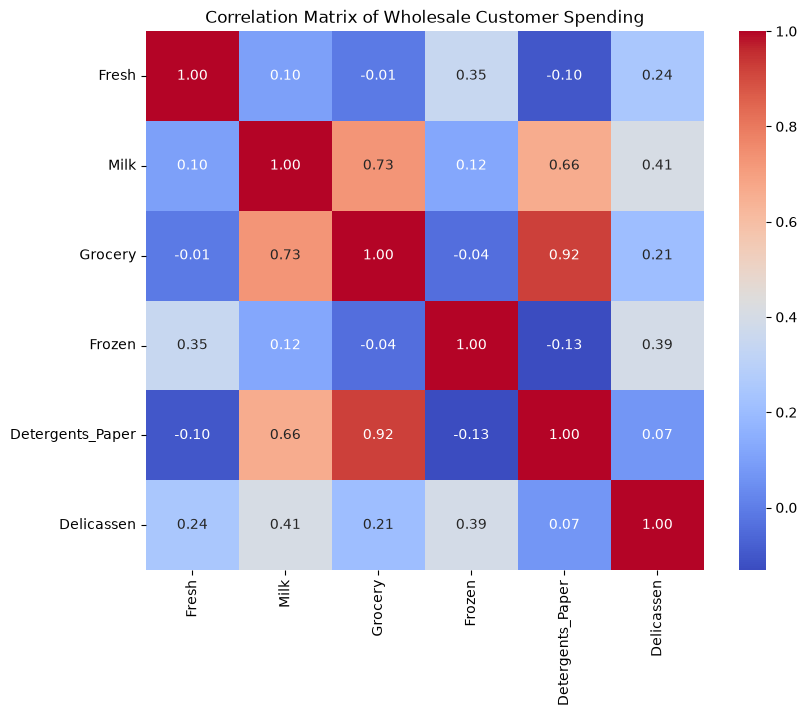

In [19]:
plt.figure(figsize=(9,7))

sns.heatmap(X.corr(),annot=True,cmap='coolwarm',fmt='.2f')

plt.title("Correlation Matrix of Wholesale Customer Spending")
plt.show()

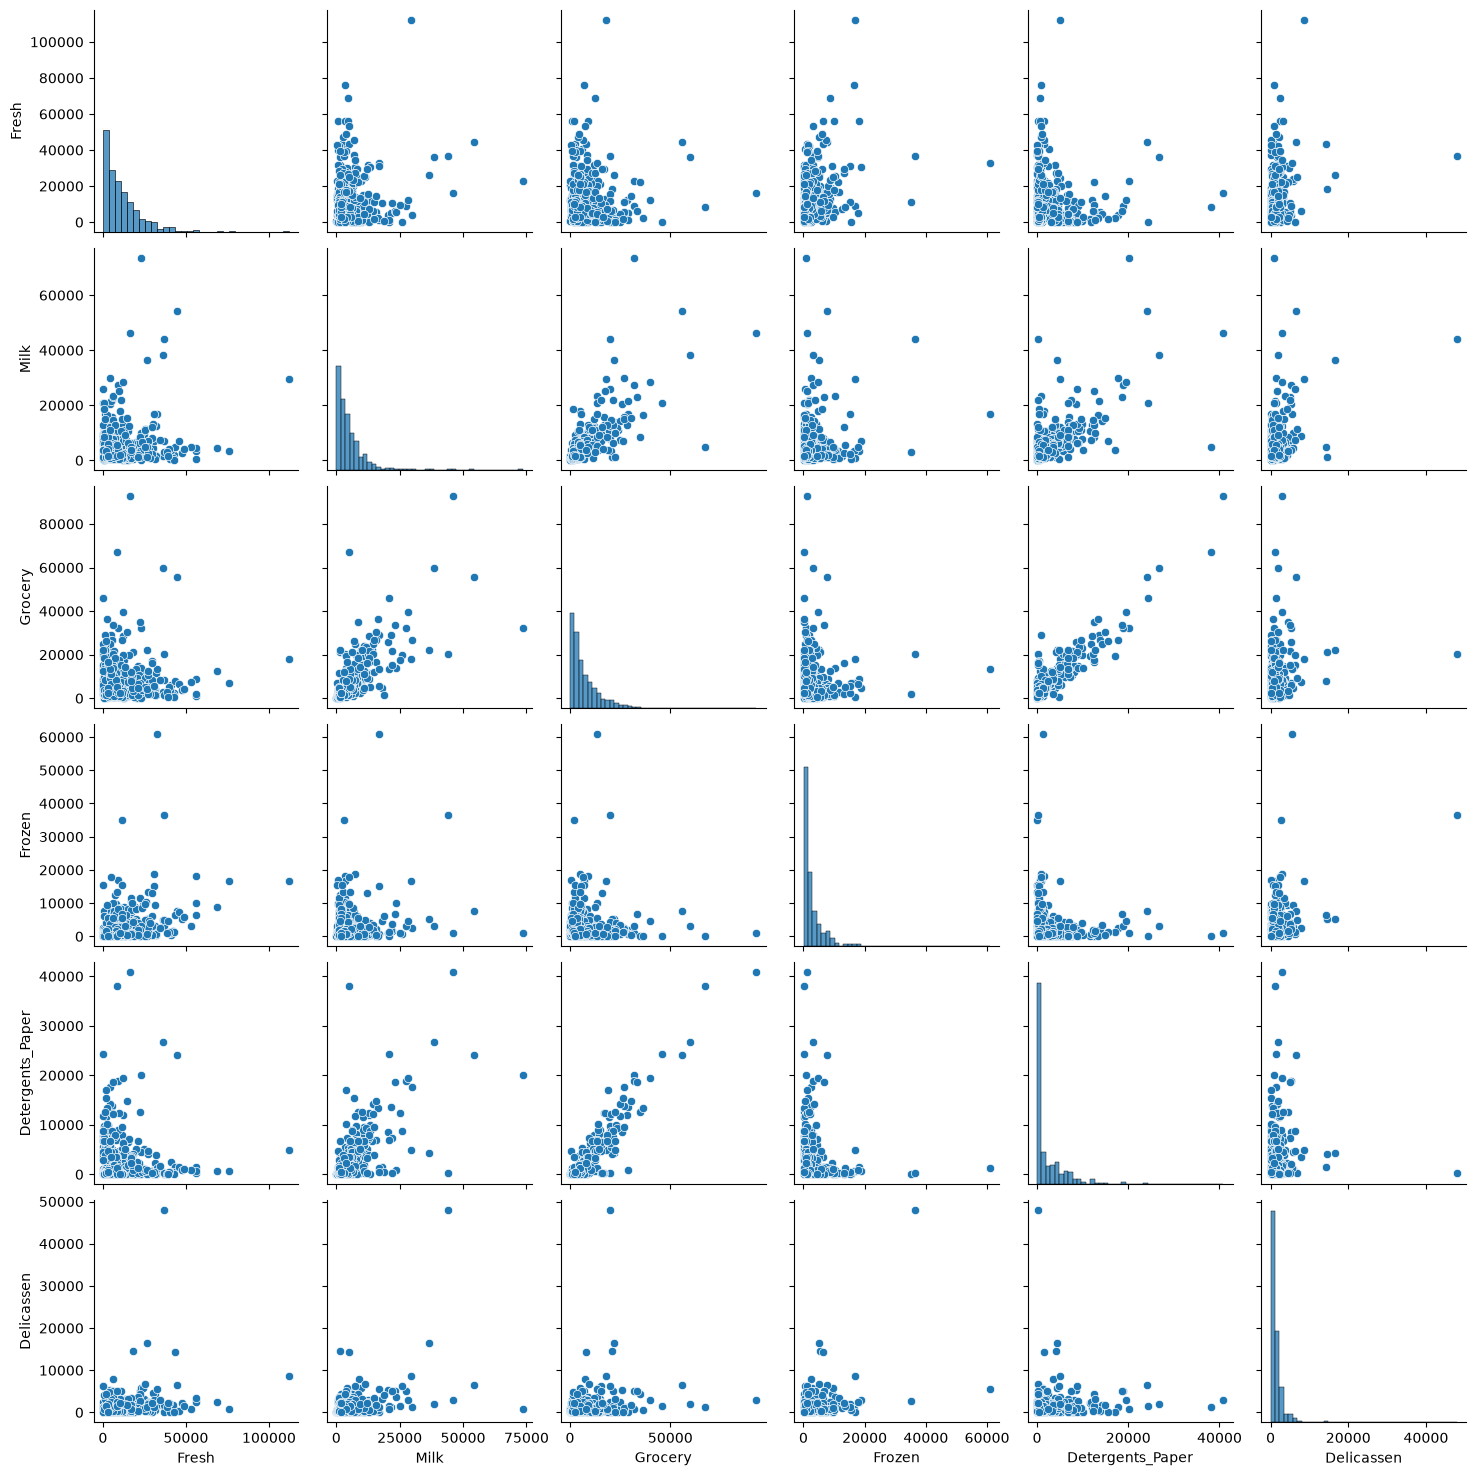

In [20]:
sns.pairplot(X)

plt.show()

In [21]:
scaler=StandardScaler()

X_scaled=scaler.fit_transform(X)

X_scaled=pd.DataFrame(X_scaled,columns=X.columns)

print("Scaled Data:")
print(X_scaled.head())

Scaled Data:
      Fresh      Milk   Grocery    Frozen  Detergents_Paper  Delicassen
0  0.052933  0.523568 -0.041115 -0.589367         -0.043569   -0.066339
1 -0.391302  0.544458  0.170318 -0.270136          0.086407    0.089151
2 -0.447029  0.408538 -0.028157 -0.137536          0.133232    2.243293
3  0.100111 -0.624020 -0.392977  0.687144         -0.498588    0.093411
4  0.840239 -0.052396 -0.079356  0.173859         -0.231918    1.299347


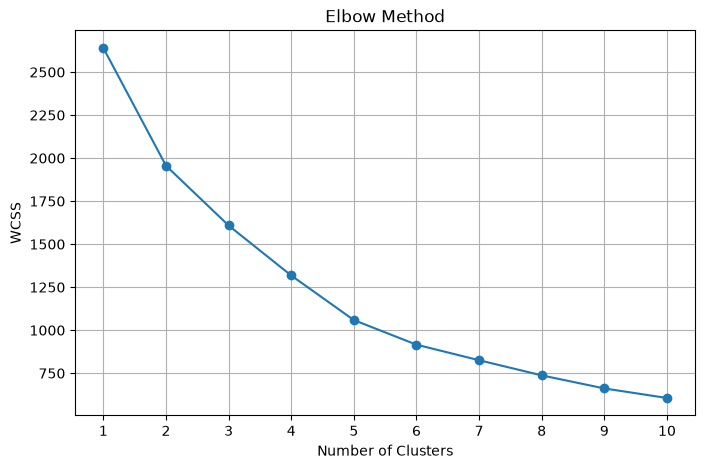

In [22]:
wcss=[]

for i in range(1,11):
    kmeans=KMeans(n_clusters=i,init='k-means++',random_state=42,n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,5))

plt.plot(range(1,11),wcss,marker='o')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.xticks(range(1,11))
plt.grid()

plt.show()

In [23]:
optimal_k=5

kmeans=KMeans(n_clusters=optimal_k,init='k-means++',random_state=42,n_init=10)

kmeans_labels=kmeans.fit_predict(X_scaled)

df['KMeans_Cluster']=kmeans_labels

print("K-Means Clustering Results:")
print(df[['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicassen','KMeans_Cluster']].head(10))

K-Means Clustering Results:
   Fresh   Milk  Grocery  Frozen  Detergents_Paper  Delicassen  KMeans_Cluster
0  12669   9656     7561     214              2674        1338               0
1   7057   9810     9568    1762              3293        1776               3
2   6353   8808     7684    2405              3516        7844               3
3  13265   1196     4221    6404               507        1788               0
4  22615   5410     7198    3915              1777        5185               2
5   9413   8259     5126     666              1795        1451               0
6  12126   3199     6975     480              3140         545               0
7   7579   4956     9426    1669              3321        2566               0
8   5963   3648     6192     425              1716         750               0
9   6006  11093    18881    1159              7425        2098               3


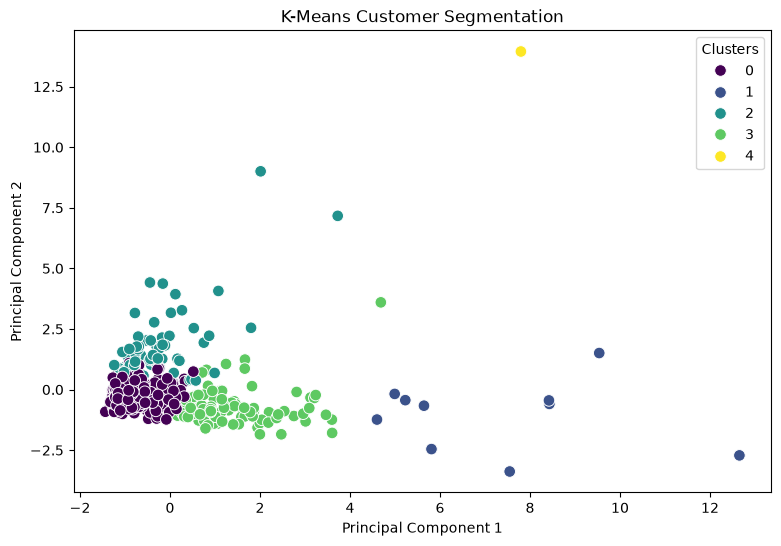

In [24]:
from sklearn.decomposition import PCA

pca=PCA(n_components=2)

X_pca=pca.fit_transform(X_scaled)

plt.figure(figsize=(9,6))

sns.scatterplot(
    x=X_pca[:,0],
    y=X_pca[:,1],
    hue=kmeans_labels,
    palette='viridis',
    s=70
)

plt.title("K-Means Customer Segmentation")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Clusters")
plt.show()

In [25]:
Z=linkage(X_scaled,method='ward')

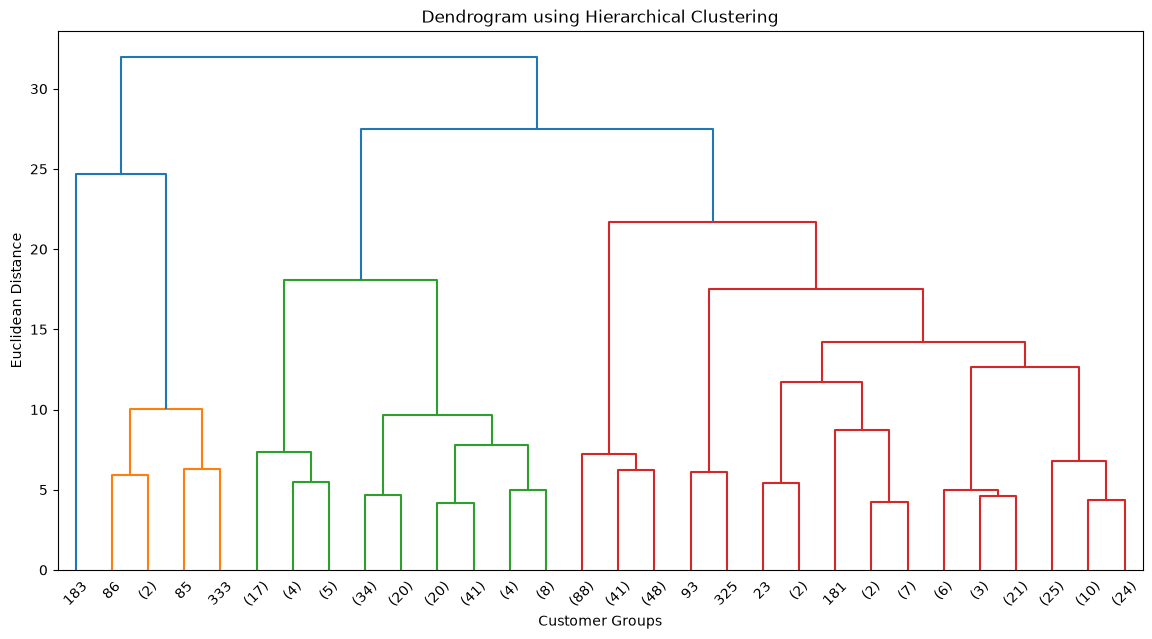

In [26]:
plt.figure(figsize=(14,7))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True
)

plt.title("Dendrogram using Hierarchical Clustering")
plt.xlabel("Customer Groups")
plt.ylabel("Euclidean Distance")
plt.show()

In [27]:
hc=AgglomerativeClustering(n_clusters=optimal_k,linkage='ward')

hc_labels=hc.fit_predict(X_scaled)

df['Hierarchical_Cluster']=hc_labels

print("Hierarchical Clustering Results:")
print(df[['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicassen','Hierarchical_Cluster']].head(10))

Hierarchical Clustering Results:
   Fresh   Milk  Grocery  Frozen  Detergents_Paper  Delicassen  \
0  12669   9656     7561     214              2674        1338   
1   7057   9810     9568    1762              3293        1776   
2   6353   8808     7684    2405              3516        7844   
3  13265   1196     4221    6404               507        1788   
4  22615   5410     7198    3915              1777        5185   
5   9413   8259     5126     666              1795        1451   
6  12126   3199     6975     480              3140         545   
7   7579   4956     9426    1669              3321        2566   
8   5963   3648     6192     425              1716         750   
9   6006  11093    18881    1159              7425        2098   

   Hierarchical_Cluster  
0                     0  
1                     0  
2                     0  
3                     4  
4                     2  
5                     0  
6                     0  
7                     0  
8     

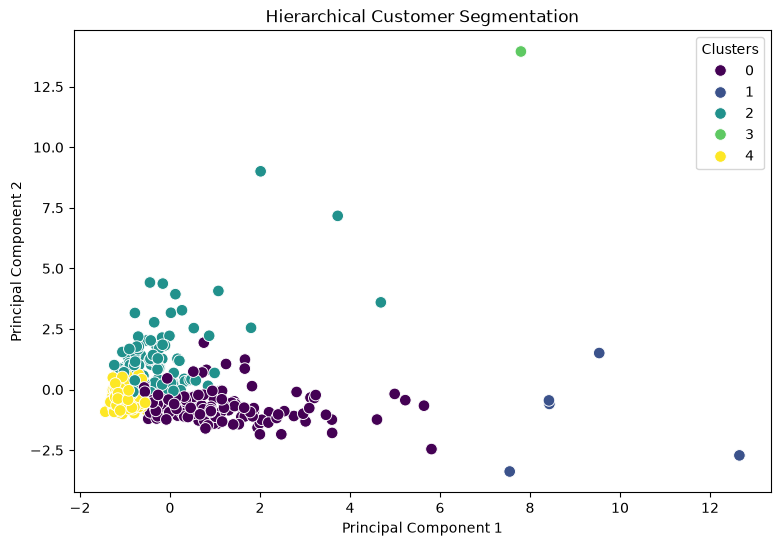

In [28]:
plt.figure(figsize=(9,6))

sns.scatterplot(
    x=X_pca[:,0],
    y=X_pca[:,1],
    hue=hc_labels,
    palette='viridis',
    s=70
)

plt.title("Hierarchical Customer Segmentation")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Clusters")
plt.show()

In [29]:
kmeans_sil=silhouette_score(X_scaled,kmeans_labels)
hc_sil=silhouette_score(X_scaled,hc_labels)

kmeans_db=davies_bouldin_score(X_scaled,kmeans_labels)
hc_db=davies_bouldin_score(X_scaled,hc_labels)

kmeans_ch=calinski_harabasz_score(X_scaled,kmeans_labels)
hc_ch=calinski_harabasz_score(X_scaled,hc_labels)

comparison=pd.DataFrame({
    'Algorithm':['K-Means','Hierarchical'],
    'Silhouette Score':[kmeans_sil,hc_sil],
    'Davies-Bouldin Index':[kmeans_db,hc_db],
    'Calinski-Harabasz Score':[kmeans_ch,hc_ch]
})

print("Performance Comparison:")
print(comparison.round(4))

Performance Comparison:
      Algorithm  Silhouette Score  Davies-Bouldin Index  \
0       K-Means            0.3690                0.9125   
1  Hierarchical            0.2399                0.9727   

   Calinski-Harabasz Score  
0                 162.4134  
1                 128.6450  


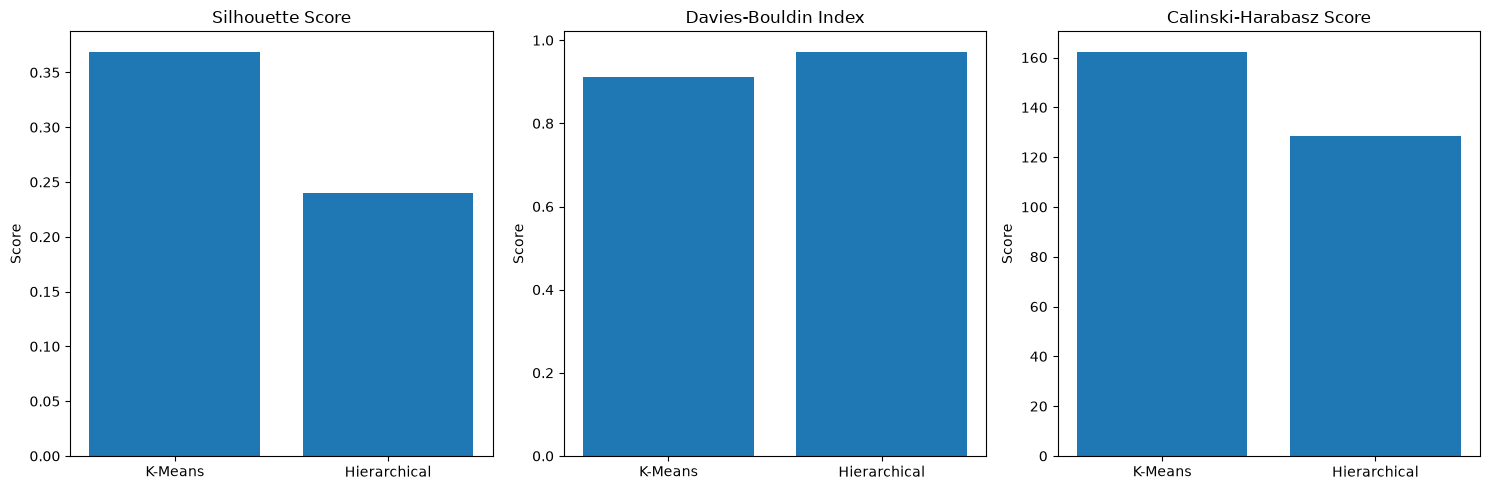

In [30]:
fig,axes=plt.subplots(1,3,figsize=(15,5))

metrics=['Silhouette Score','Davies-Bouldin Index','Calinski-Harabasz Score']

for i,metric in enumerate(metrics):
    axes[i].bar(comparison['Algorithm'],comparison[metric])
    axes[i].set_title(metric)
    axes[i].set_ylabel("Score")

plt.tight_layout()
plt.show()

In [31]:
print("K-Means Customer Segment Analysis:")

kmeans_analysis=df.groupby('KMeans_Cluster')[
    ['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicassen']
].mean().round(2)

print(kmeans_analysis)

K-Means Customer Segment Analysis:
                   Fresh      Milk   Grocery    Frozen  Detergents_Paper  \
KMeans_Cluster                                                             
0                9092.16   2967.76   3807.41   2271.76            989.81   
1               15964.90  34708.50  48536.90   3054.60          24875.20   
2               32957.98   4997.35   5884.76   8422.84            954.60   
3                5754.17  10866.60  16607.10   1464.12           7202.88   
4               36847.00  43950.00  20170.00  36534.00            239.00   

                Delicassen  
KMeans_Cluster              
0                   978.96  
1                  2942.80  
2                  2462.97  
3                  1813.39  
4                 47943.00  


In [32]:
print("Hierarchical Customer Segment Analysis:")

hc_analysis=df.groupby('Hierarchical_Cluster')[
    ['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicassen']
].mean().round(2)

print(hc_analysis)

Hierarchical Customer Segment Analysis:
                         Fresh      Milk   Grocery    Frozen  \
Hierarchical_Cluster                                           
0                      5794.24   9419.89  13761.74   1461.76   
1                     25603.00  43460.60  61472.20   2636.00   
2                     27256.28   4914.38   5931.46   6277.77   
3                     36847.00  43950.00  20170.00  36534.00   
4                      7876.25   1902.63   2534.54   2403.38   

                      Detergents_Paper  Delicassen  
Hierarchical_Cluster                                
0                              5913.38     1577.61  
1                             29974.20     2708.80  
2                              1184.97     2272.94  
3                               239.00    47943.00  
4                               507.14      744.05  


In [33]:
print("K-Means Cluster Counts:")
print(df['KMeans_Cluster'].value_counts().sort_index())

print("\nHierarchical Cluster Counts:")
print(df['Hierarchical_Cluster'].value_counts().sort_index())

K-Means Cluster Counts:
KMeans_Cluster
0    270
1     10
2     63
3     96
4      1
Name: count, dtype: int64

Hierarchical Cluster Counts:
Hierarchical_Cluster
0    153
1      5
2    104
3      1
4    177
Name: count, dtype: int64


In [34]:
print("EXPERIMENT NO. 9")
print("K-Means and Hierarchical Clustering")

print("\nTotal Customers:",len(df))

print("\nK-Means Clusters:",df['KMeans_Cluster'].nunique())

print("Hierarchical Clusters:",df['Hierarchical_Cluster'].nunique())

print("\nK-Means Silhouette Score:",round(kmeans_sil,4))

print("Hierarchical Silhouette Score:",round(hc_sil,4))

print("\nExperiment Completed Successfully!")

EXPERIMENT NO. 9
K-Means and Hierarchical Clustering

Total Customers: 440

K-Means Clusters: 5
Hierarchical Clusters: 5

K-Means Silhouette Score: 0.369
Hierarchical Silhouette Score: 0.2399

Experiment Completed Successfully!


In [ ]:
=